# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170321         # <-- your full roll number
NAME = "GURLEEN KAUR"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170321   Name: GURLEEN KAUR   Fingerprint: 3E0DA679   Tickets: 13

Ticket_ID                                                                             Ticket_Text
      T01                              The Matlab keeps disconnecting. Is there another solution?
      T02                                          Re-installing didn't help; log-in still fails!
      T03                                                           Version 2.0.1 crashes at 99%.
      T04                            I reinstalled the VPN while uploading the file. Please help.
      T05                               The student portal was working yesterday. This is urgent.
      T06     Wifi crashes while opening while uploading the file. The same problem occurs again.
      T07                                                             My roll no. is 1023-03-021.
      T08   I am unable to use the lms when connected to campus Wi-Fi. Is there another solution?
      T09           Lms is not wor

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:


# Q1: Preprocessing summary

records = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    records.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation_Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique_Tokens": len(set(result["tokens"])),
        "Final_Tokens": len(result["final"])
    })

summary_df = pd.DataFrame(records)

# Add a total row to count-based columns
count_columns = [
    "Sentences", "Tokens", "Punctuation_Tokens",
    "Stopwords", "Unique_Tokens", "Final_Tokens"
]

total_row = {"Ticket_ID": "TOTAL"}

for col in count_columns:
    total_row[col] = summary_df[col].sum()

summary_df = pd.concat(
    [summary_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(summary_df)

# Display details for the first ticket
selected_id = df.iloc[0]["Ticket_ID"]
selected_text = df.iloc[0]["Ticket_Text"]

result = process_ticket(selected_text)

print("Ticket ID:", selected_id)
print("Ticket text:", selected_text)
print("\nTokens:", result["tokens"])
print("\nPunctuation tokens:", result["punct"])
print("\nStopwords:", result["stops"])
print("\nFinal tokens:", result["final"])









,Ticket_ID,Sentences,Tokens,Punctuation_Tokens,Stopwords,Unique_Tokens,Final_Tokens
0,T01,2,10,2,3,10,5
1,T02,1,9,2,1,9,6
2,T03,1,7,2,1,7,4
3,T04,2,12,2,4,10,6
4,T05,2,11,2,4,10,5
5,T06,2,15,2,6,12,7
6,T07,2,7,2,3,6,2
7,T08,2,18,2,8,17,8
8,T09,2,14,2,6,13,6
9,T10,2,14,2,4,13,8


Ticket ID: T01
Ticket text: The Matlab keeps disconnecting. Is there another solution?

Tokens: ['the', 'matlab', 'keeps', 'disconnecting', '.', 'is', 'there', 'another', 'solution', '?']

Punctuation tokens: ['.', '?']

Stopwords: ['the', 'is', 'there']

Final tokens: ['matlab', 'keeps', 'disconnecting', 'another', 'solution']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

for line in TEST_LINES:
    words = re.findall(r"\b[A-Za-z]+\b", line)
    print("Text:", line)
    print("Words:", words)
    print()

for line in TEST_LINES:
    numbers = re.findall(r"\d+(?:[.,]\d+)*", line)
    print("Text:", line)
    print("Numbers:", numbers)
    print()

for line in TEST_LINES:
    capitalized = re.findall(r"\b[A-Z][a-z]*\b", line)
    print("Text:", line)
    print("Capitalized words:", capitalized)
    print()

import re

for line in TEST_LINES:
    cleaned = line

    # Replace email addresses
    cleaned = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        cleaned
    )

    # Replace URLs, including www addresses
    cleaned = re.sub(
        r"(?:https?://|www\.)\S+",
        "<URL>",
        cleaned
    )

    # Replace phone numbers
    cleaned = re.sub(
        r"(?<!\w)(?:\+91[\s-]?)?(?:\d{5}[\s-]?\d{5}|\d{4}[\s-]\d{3}[\s-]\d{4})(?!\w)",
        "<PHONE>",
        cleaned
    )

    print("Original:", line)
    print("Cleaned: ", cleaned)
    print()


Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words: ['Mail', 'it', 'helpdesk', 'thapar', 'edu', 'or', 'a', 'b', 'c', 'dept', 'univ', 'ac', 'in', 'visit', 'https', 'lms', 'thapar', 'edu', 'help', 'or', 'www', 'thapar', 'edu', 'it']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words: ['Call', 'or', 'Version', 'is', 'done', 'fee', 'Rs']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words: ['The', 'state', 'of', 'the', 'art', 'lab', 'isn', 't', 'open', 'log', 'in', 'at', 'p', 'm', 'didn', 't', 'work']

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Numbers: []

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code

from nltk.tokenize import RegexpTokenizer, word_tokenize

custom_tokenizer = RegexpTokenizer(
    r"[A-Za-z]+(?:[-'][A-Za-z]+)*|\d+(?:[.,]\d+)*|[^\w\s]"
)

for line in TEST_LINES:
    print("Text:", line)
    print("Custom tokens:", custom_tokenizer.tokenize(line))
    print()

for line in TEST_LINES:
    print("Original:", line)
    print("word_tokenize:", word_tokenize(line))
    print("RegexpTokenizer:", custom_tokenizer.tokenize(line))
    print("-" * 60)


Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokens: ['Mail', 'it', '.', 'helpdesk', '@', 'thapar', '.', 'edu', 'or', 'a', '.', 'b-c', '@', 'dept', '.', 'univ', '.', 'ac', '.', 'in', ';', 'visit', 'https', ':', '/', '/', 'lms', '.', 'thapar', '.', 'edu', '/', 'help', 'or', 'www', '.', 'thapar', '.', 'edu', '/', 'it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokens: ['Call', '+', '91', '98765', '43210', ',', '+', '91', '-', '98765', '-', '43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom tokens: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.uni

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code

import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.stem import PorterStemmer, LancasterStemmer, WordNetLemmatizer

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

unique_final_tokens = sorted({
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
})

print("Number of unique final tokens:", len(unique_final_tokens))
print(unique_final_tokens)

results = []

for word in unique_final_tokens:
    results.append({
        "Original": word,
        "Porter Stem": porter.stem(word),
        "Lancaster Stem": lancaster.stem(word),
        "WordNet Lemma": lemmatizer.lemmatize(word)
    })

results_df = pd.DataFrame(results)
display(results_df)

results = []

for word in unique_final_tokens:
    results.append({
        "Original": word,
        "WordNet Noun": lemmatizer.lemmatize(word, pos="n"),
        "WordNet Verb": lemmatizer.lemmatize(word, pos="v")
    })

wordnet_df = pd.DataFrame(results)
display(wordnet_df)

%pip install -q spacy
!python -m spacy download en_core_web_sm

import spacy

nlp = spacy.load("en_core_web_sm")

spacy_results = []

for word in unique_final_tokens:
    doc = nlp(word)
    spacy_results.append({
        "Original": word,
        "spaCy Lemma": doc[0].lemma_
    })

spacy_df = pd.DataFrame(spacy_results)
display(spacy_df)

print("Ticket count:", len(df))
print("Fingerprint: 3E0DA679")
print("Q1 summary shape:", summary_df.shape)
print("Unique final tokens:", len(unique_final_tokens))
print("Q4 comparison shape:", results_df.shape)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Number of unique final tokens: 51
['1023-03-021', '2.0.1', '99', 'another', 'assignment', 'campus', 'computer', 'connected', 'crashes', 'deadline', 'disconnecting', 'failed', 'fails', 'file', 'help', 'keeps', 'lms', 'log-in', 'matlab', "n't", 'occurs', 'open', 'opening', 'password', 'please', 'portal', 'problem', 're-installing', 'reinstalled', 'resetting', 'resolve', 'restarting', 'roll', 'running', 'server', 'slowly', 'solution', 'still', 'student', 'tried', 'unable', 'uploading', 'urgent', 'use', 'version', 'vpn', 'wi-fi', 'wifi', 'working', 'works', 'yesterday']


,Original,Porter Stem,Lancaster Stem,WordNet Lemma
0,1023-03-021,1023-03-021,1023-03-021,1023-03-021
1,2.0.1,2.0.1,2.0.1,2.0.1
2,99,99,99,99
3,another,anoth,anoth,another
4,assignment,assign,assign,assignment
5,campus,campu,camp,campus
6,computer,comput,comput,computer
7,connected,connect,connect,connected
8,crashes,crash,crash,crash
9,deadline,deadlin,deadlin,deadline


,Original,WordNet Noun,WordNet Verb
0,1023-03-021,1023-03-021,1023-03-021
1,2.0.1,2.0.1,2.0.1
2,99,99,99
3,another,another,another
4,assignment,assignment,assignment
5,campus,campus,campus
6,computer,computer,computer
7,connected,connected,connect
8,crashes,crash,crash
9,deadline,deadline,deadline


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 87.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


,Original,spaCy Lemma
0,1023-03-021,1023
1,2.0.1,2.0.1
2,99,99
3,another,another
4,assignment,assignment
5,campus,campus
6,computer,computer
7,connected,connect
8,crashes,crash
9,deadline,deadline


Ticket count: 13
Fingerprint: 3E0DA679
Q1 summary shape: (14, 7)
Unique final tokens: 51
Q4 comparison shape: (51, 4)


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1 token count: 153
S2 token count: 128
S3 token count: 76
S4 token count: 76


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,153,78,0.5098
1,S2 - Without punctuation,128,73,0.5703
2,S3 - Final tokens,76,51,0.6711
3,S4 - Porter stemmed,76,48,0.6316


Top 10 words in S1 (all tokens):


,Word,Frequency
0,.,18
1,the,11
2,is,8
3,another,4
4,?,4
5,while,4
6,to,4
7,there,3
8,solution,3
9,help,3


Top 10 words in S3 (final tokens):


,Word,Frequency
0,another,4
1,solution,3
2,help,3
3,uploading,3
4,file,3
5,please,3
6,portal,3
7,n't,2
8,crashes,2
9,student,2


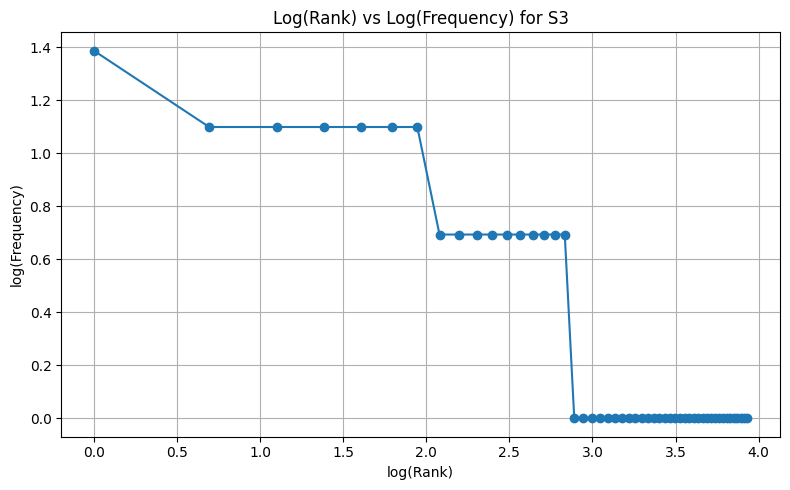

In [ ]:
# Your code

from collections import Counter
from nltk.stem import PorterStemmer

porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)
    S1.extend(result["tokens"])
    S2.extend([t for t in result["tokens"] if not is_punct(t)])
    S3.extend(result["final"])

S4 = [porter.stem(token) for token in S3]

print("S1 token count:", len(S1))
print("S2 token count:", len(S2))
print("S3 token count:", len(S3))
print("S4 token count:", len(S4))

import pandas as pd

corpora = {
    "S1 - All tokens": S1,
    "S2 - Without punctuation": S2,
    "S3 - Final tokens": S3,
    "S4 - Porter stemmed": S4
}

stats = []

for name, tokens in corpora.items():
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
display(stats_df)

from collections import Counter

print("Top 10 words in S1 (all tokens):")
display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=["Word", "Frequency"]
))

print("Top 10 words in S3 (final tokens):")
display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=["Word", "Frequency"]
))

import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

frequency_counts = Counter(S3).most_common()

ranks = np.arange(1, len(frequency_counts) + 1)
frequencies = np.array([count for word, count in frequency_counts])

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(frequencies), marker="o", linestyle="-")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.tight_layout()
plt.show()


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*